# 14 - DC-CRI: Risk-Tolerance and Verification-Horizon Sensitivity, and the LOSO Summary Figure

**Questions:**
1. Does the prescribed activation-risk tolerance $\epsilon_{\mathrm{risk}}$ trade off exactly as
   intended -- tighter tolerance gives a more conservative threshold and lower FAR, looser
   tolerance gives more availability -- and does that trade-off actually hold up under genuine
   LOSO out-of-scenario evaluation, not just in-sample?
2. Do the paper's conclusions change with the verification horizon $T_H\in\{0.1,0.25,0.5,1.0\}$ s?

Both sensitivities are evaluated with the *same* full 8-fold LOSO protocol as notebook 13 (not an
in-sample characterization), since notebook 13 found a sharp generalization dependence on
$\eta_A^{\star}$: in-sample calibration quality alone would not have revealed it.

Outputs: `results/results_dc_cri_risk_sensitivity.csv`, `results/results_dc_cri_horizon_sensitivity.csv`,
`Figures/Fig_dc_cri_loso_summary.pdf`, `Figures/Fig_dc_cri_representative_trajectory.pdf`.

In [1]:
import sys, os, time
sys.path.insert(0, os.path.abspath(".."))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from cri_microgrid.config import (PlantParams, ControllerParams, ConstraintParams, CRIParams,
                                   ProbeParams, ProfileParams, SimulationParams)
from cri_microgrid import scenarios, sim, metrics, plotstyle
from cri_microgrid import dc_calibration as dcc

plotstyle.apply_style()
RESULTS_DIR = os.path.abspath("../results")
FIG_DIR = os.path.abspath("../Figures")
os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)

pp = PlantParams()
cp = ControllerParams()
cons = ConstraintParams()
crip = CRIParams()
probep = ProbeParams()
prof = ProfileParams()

LAMBDA_H = 2.0
EPS_RISK_PRINCIPAL = 0.01
T_H_PRINCIPAL = 0.5
N_SEED_CAL = 5

SCENARIO_BUILDERS = {
    "S1": lambda: scenarios.build_S1(pp, prof, T_end=40.0),
    "S2": lambda: scenarios.build_S2(pp, prof, T_end=40.0),
    "S3": lambda: scenarios.build_S3(pp, prof, T_end=40.0),
    "S4": lambda: scenarios.build_S4(pp, prof, T_end=40.0),
    "S5": lambda: scenarios.build_S5(pp, prof, ramp_kind="fast", T_end=40.0),
    "S6": lambda: scenarios.build_S6(pp, prof, noise_level_pct=1.0, T_end=40.0),
    "S7": lambda: scenarios.build_S7(pp, prof, T_end=40.0, kind="vsc2_outage"),
    "S8": lambda: scenarios.build_S8(pp, prof, T_end=50.0),
}
SCENARIO_ORDER = list(SCENARIO_BUILDERS.keys())
NOISY_SCENARIOS = {"S6", "S8"}       # match notebook 13 exactly
N_SEED_EVAL_NOISY = 5                # extra held-out-evaluation seeds for S6, S8

## Shared helper: one full LOSO pass for a given (H, eps_risk), returning per-fold and aggregate metrics

Calibration trajectories (seed 0..N_SEED_CAL-1, EC-CRI-supervised) are generated once per $H$ (since
the readiness vectors $\Gamma_k$ do not depend on $H$ or $\epsilon_{\mathrm{risk}}$, only the label
$z_k^{(H)}$ does) and reused across every $\epsilon_{\mathrm{risk}}$ value swept at that horizon.

In [2]:
def generate_calibration_trajectories(n_seed_cal=N_SEED_CAL):
    cal = {name: [] for name in SCENARIO_ORDER}
    for name, builder in SCENARIO_BUILDERS.items():
        scenario = builder()
        for seed in range(n_seed_cal):
            simp = SimulationParams(T_end=scenario.T_end, seed=seed, strategy="cri")
            lg = sim.run_closed_loop(scenario, pp, cp, cons, crip, probep, simp)
            cal[name].append(dcc.collect_trajectory(lg, cons, name, seed, pp.Ts))
    return cal


def run_full_loso(cal_trajectories, H, eps_risk, lambda_H=LAMBDA_H, eval_seed=1):
    """One full 8-fold LOSO pass (calibration + DC-CRI-only held-out evaluation) at
    a given (H, eps_risk). For each held-out scenario, evaluates over eval_seed=1
    alone for the six deterministic scenarios, and over N_SEED_EVAL_NOISY=5 seeds
    for S6/S8 (averaged within the scenario first) -- exactly the convention used
    by notebook 13's Package 2A, so that this function's aggregate is directly
    comparable to Table tab:loso_results at matching (eps_risk, T_H). Returns
    (fold_rows_df, agg_dict); fold_rows_df has exactly one row per held-out
    scenario (already seed-averaged for S6/S8), so agg_dict's means/std are
    automatically equal-scenario-weighted.
    """
    fold_rows = []
    for held_out in SCENARIO_ORDER:
        pool = [t for name in SCENARIO_ORDER if name != held_out for t in cal_trajectories[name]]
        outcome = dcc.calibrate_dc_cri(pool, H=H, eps_risk=eps_risk, lambda_H=lambda_H, crip_template=crip)
        crip_dc = dcc.dc_cri_params_from_outcome(outcome, crip)

        eval_seeds = [eval_seed] + (list(range(N_SEED_EVAL_NOISY)) if held_out in NOISY_SCENARIOS else [])
        eval_seeds = sorted(set(eval_seeds))

        seed_rows = []
        for seed in eval_seeds:
            scenario = SCENARIO_BUILDERS[held_out]()
            simp = SimulationParams(T_end=scenario.T_end, seed=seed, strategy="cri")
            lg = sim.run_closed_loop(scenario, pp, cp, cons, crip_dc, probep, simp)
            z_H = dcc.finite_horizon_label(lg, cons, H)
            seed_rows.append(dict(
                N_FA=metrics.false_activation_count_horizon(lg["s"], z_H),
                FAR=metrics.far(lg["s"], z_H), FDR=metrics.fdr(lg["s"], z_H),
                A_c=metrics.controller_availability(lg["s"]),
            ))
        seed_df = pd.DataFrame(seed_rows)
        seed_mean = seed_df.mean()

        fold_rows.append(dict(
            held_out=held_out, feasible=outcome.feasible, eta_A=outcome.eta_A,
            omega=outcome.omega.copy(),
            N_FA=seed_mean["N_FA"], FAR=seed_mean["FAR"], FDR=seed_mean["FDR"], A_c=seed_mean["A_c"],
        ))
    df = pd.DataFrame(fold_rows)
    agg = dict(
        n_feasible=int(df["feasible"].sum()),
        eta_A_mean=df["eta_A"].mean(), eta_A_std=df["eta_A"].std(),
        N_FA=df["N_FA"].mean(), FAR=df["FAR"].mean(), FDR=df["FDR"].mean(), A_c=df["A_c"].mean(),
    )
    return df, agg


## Risk-tolerance sensitivity (LOSO-aggregate, $T_H=0.5$~s)

In [3]:
H_principal = dcc.samples_to_horizon(T_H_PRINCIPAL, pp.Ts)
cal_traj_Hprincipal = generate_calibration_trajectories()

RISK_LEVELS = [0.01, 0.025, 0.05, 0.10]
risk_fold_dfs = {}
risk_rows = []
t0 = time.time()
for eps in RISK_LEVELS:
    fold_df, agg = run_full_loso(cal_traj_Hprincipal, H_principal, eps)
    risk_fold_dfs[eps] = fold_df
    risk_rows.append(dict(eps_risk=eps, **agg))
    print(f"eps_risk={eps:<6} eta_A*={agg['eta_A_mean']:.3f}+/-{agg['eta_A_std']:.3f}  "
          f"FAR={agg['FAR']:.4f}  A_c={agg['A_c']:.4f}  FDR={agg['FDR']:.4f}  feasible={agg['n_feasible']}/8")
print(f"\nRisk-tolerance sweep completed in {time.time()-t0:.1f} s")

risk_df = pd.DataFrame(risk_rows).set_index("eps_risk")
risk_df.to_csv(os.path.join(RESULTS_DIR, "results_dc_cri_risk_sensitivity.csv"))
display(risk_df.round(4))

eps_risk=0.01   eta_A*=0.503+/-0.103  FAR=0.2172  A_c=0.8065  FDR=0.0538  feasible=8/8
eps_risk=0.025  eta_A*=0.218+/-0.080  FAR=0.4083  A_c=0.9518  FDR=0.0000  feasible=8/8
eps_risk=0.05   eta_A*=0.134+/-0.041  FAR=0.6457  A_c=0.9976  FDR=0.0000  feasible=8/8
eps_risk=0.1    eta_A*=0.119+/-0.050  FAR=0.6500  A_c=1.0000  FDR=0.0000  feasible=8/8

Risk-tolerance sweep completed in 64.5 s


,n_feasible,eta_A_mean,eta_A_std,N_FA,FAR,FDR,A_c
eps_risk,,,,,,,
0.010,8,0.5030,0.1028,374.300,0.2172,0.0538,0.8065
0.025,8,0.2180,0.0798,619.350,0.4083,0.0000,0.9518
0.050,8,0.1342,0.0415,826.675,0.6457,0.0000,0.9976
0.100,8,0.1191,0.0504,825.425,0.6500,0.0000,1.0000


## Verification-horizon sensitivity (LOSO-aggregate, $\epsilon_{\mathrm{risk}}=0.01$)

In [4]:
T_H_LEVELS = [0.1, 0.25, 0.5, 1.0]
horizon_rows = []
horizon_fold_dfs = {}
t0 = time.time()
for T_H in T_H_LEVELS:
    H = dcc.samples_to_horizon(T_H, pp.Ts)
    if H == H_principal:
        cal_traj_H = cal_traj_Hprincipal  # Gamma/sigma/viol don't depend on H; reuse directly
    else:
        cal_traj_H = generate_calibration_trajectories()  # only re-simulated because our helper regenerates by scenario; z_k^(H) itself is recomputed from viol either way
    fold_df, agg = run_full_loso(cal_traj_H, H, EPS_RISK_PRINCIPAL)
    horizon_fold_dfs[T_H] = fold_df
    horizon_rows.append(dict(T_H=T_H, H_samples=H, **agg))
    print(f"T_H={T_H:<5} (H={H:3d})  eta_A*={agg['eta_A_mean']:.3f}+/-{agg['eta_A_std']:.3f}  "
          f"N_FA={agg['N_FA']:.1f}  FAR={agg['FAR']:.4f}  FDR={agg['FDR']:.4f}  A_c={agg['A_c']:.4f}")
print(f"\nHorizon sweep completed in {time.time()-t0:.1f} s")

horizon_df = pd.DataFrame(horizon_rows).set_index("T_H")
horizon_df.to_csv(os.path.join(RESULTS_DIR, "results_dc_cri_horizon_sensitivity.csv"))
display(horizon_df.round(4))

T_H=0.1   (H=  5)  eta_A*=0.243+/-0.088  N_FA=370.0  FAR=0.2688  FDR=0.0334  A_c=0.8613
T_H=0.25  (H= 12)  eta_A*=0.302+/-0.108  N_FA=385.6  FAR=0.2284  FDR=0.0033  A_c=0.8440
T_H=0.5   (H= 25)  eta_A*=0.503+/-0.103  N_FA=374.3  FAR=0.2172  FDR=0.0538  A_c=0.8065
T_H=1.0   (H= 50)  eta_A*=0.581+/-0.135  N_FA=136.4  FAR=0.0940  FDR=0.2732  A_c=0.5859

Horizon sweep completed in 159.8 s


,H_samples,n_feasible,eta_A_mean,eta_A_std,N_FA,FAR,FDR,A_c
T_H,,,,,,,,
0.10,5,8,0.2435,0.0875,370.025,0.2688,0.0334,0.8613
0.25,12,8,0.3025,0.1080,385.625,0.2284,0.0033,0.8440
0.50,25,8,0.5030,0.1028,374.300,0.2172,0.0538,0.8065
1.00,50,8,0.5810,0.1348,136.375,0.0940,0.2732,0.5859


## Figure -- LOSO generalization and risk-availability characteristics of DC-CRI

One 4-panel figure, styled identically to `Fig_severe_dashboard_v2` (`FIG_WIDTH=7.5`, same fonts,
grid, and legend conventions): (a) per-held-out-scenario FAR, EC-CRI vs. DC-CRI; (b) risk-availability
trade-off across $\epsilon_{\mathrm{risk}}$; (c) calibrated-weight stability across the 8 folds;
(d) horizon sensitivity.

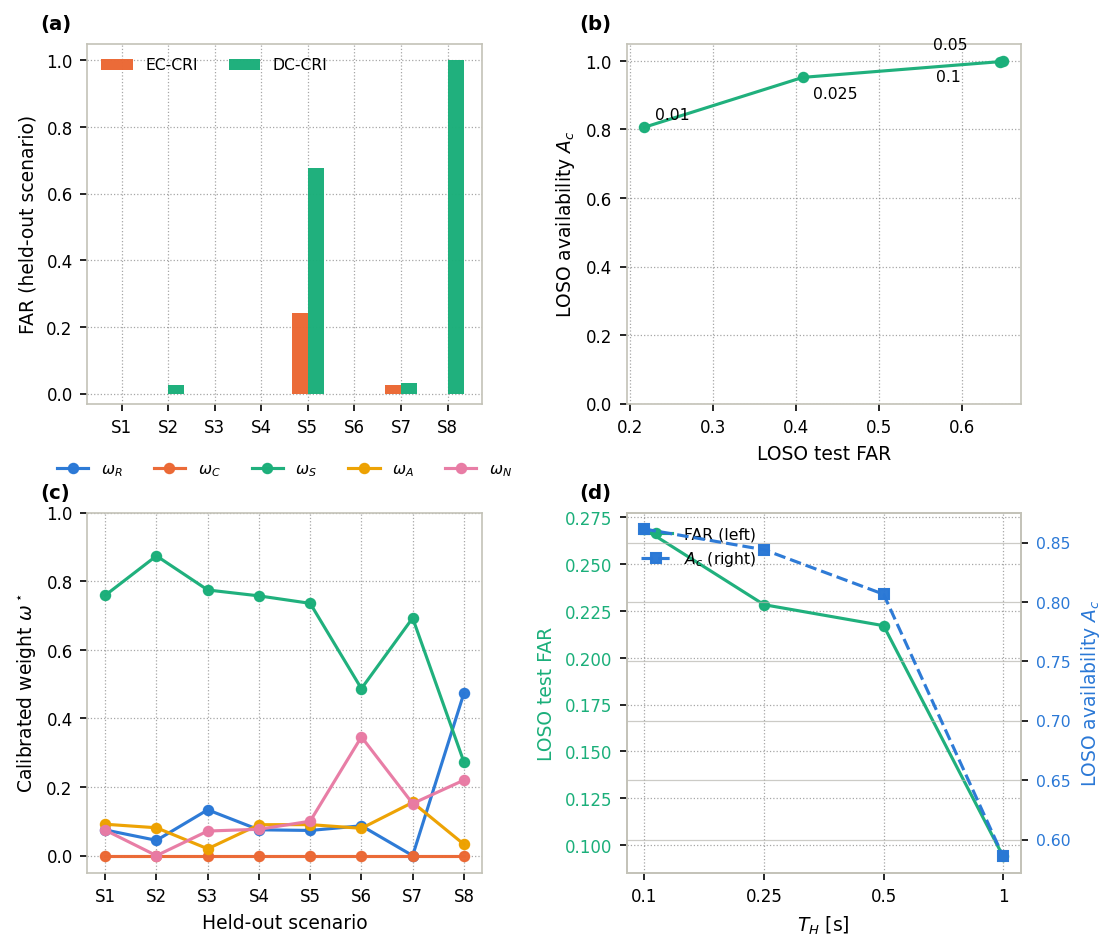

In [5]:
# ======================================================================
# Easy-to-tune figure settings (matching Fig_severe_dashboard_v2's conventions)
# ======================================================================
FIG_WIDTH = 7.5
FIG_HEIGHT = 6.4

LINE_ALPHA = 0.98
MARKER_SIZE = 4.5
LW_MAIN = 1.5

FONT_AXIS = 9.0
FONT_TICK = 8.0
FONT_LEGEND = 7.5
FONT_PANEL_LABEL = 9.5

GRID_COLOR = "gray"
GRID_ALPHA = 0.7
GRID_LW = 0.60
GRID_LS = ":"

COLOR_ECCRI = plotstyle.STRATEGY_COLORS["threshold"]
COLOR_DCCRI = plotstyle.STRATEGY_COLORS["cri"]
COLOR_DIRECT = plotstyle.STRATEGY_COLORS["direct"]


def style_grid(ax):
    ax.grid(True, color=GRID_COLOR, alpha=GRID_ALPHA, linewidth=GRID_LW, linestyle=GRID_LS)
    ax.set_axisbelow(True)


fig, axes = plt.subplots(2, 2, figsize=(FIG_WIDTH, FIG_HEIGHT))
((axA, axB), (axC, axD)) = axes

# --- Panel (a): per-held-out-scenario FAR, EC-CRI vs DC-CRI (principal settings) ---
principal_fold_df = risk_fold_dfs[EPS_RISK_PRINCIPAL].set_index("held_out").reindex(SCENARIO_ORDER)
ecri_far_by_scn = pd.read_csv(os.path.join(RESULTS_DIR, "results_dc_cri_loso_perscenario_summary.csv"),
                               index_col=[0, 1])["FAR"].xs("EC-CRI", level="method").reindex(SCENARIO_ORDER)
x = np.arange(len(SCENARIO_ORDER))
width = 0.35
axA.bar(x - width / 2, ecri_far_by_scn.values, width, color=COLOR_ECCRI, alpha=LINE_ALPHA, label="EC-CRI")
axA.bar(x + width / 2, principal_fold_df["FAR"].values, width, color=COLOR_DCCRI, alpha=LINE_ALPHA, label="DC-CRI")
axA.set_xticks(x); axA.set_xticklabels(SCENARIO_ORDER, fontsize=FONT_TICK)
axA.set_ylabel("FAR (held-out scenario)", fontsize=FONT_AXIS)
axA.set_ylim(-0.03, 1.05)
axA.legend(frameon=False, fontsize=FONT_LEGEND, ncol=2, loc="upper left")
axA.text(-0.12, 1.04, "(a)", transform=axA.transAxes, fontsize=FONT_PANEL_LABEL, fontweight="bold")
style_grid(axA)

# --- Panel (b): risk-availability trade-off across eps_risk ---
axB.plot(risk_df["FAR"], risk_df["A_c"], "o-", color=COLOR_DCCRI, lw=LW_MAIN,
         markersize=MARKER_SIZE, alpha=LINE_ALPHA)
for i, (eps, row) in enumerate(risk_df.iterrows()):
    off = [(5, 4), (5, -10), (-32, 6), (-32, -10)][i % 4]
    axB.annotate(f"{eps:g}", (row["FAR"], row["A_c"]), textcoords="offset points",
                 xytext=off, fontsize=FONT_LEGEND)
axB.set_xlabel(r"LOSO test FAR", fontsize=FONT_AXIS)
axB.set_ylabel(r"LOSO availability $A_c$", fontsize=FONT_AXIS)
axB.set_ylim(0, 1.05)
axB.text(-0.12, 1.04, "(b)", transform=axB.transAxes, fontsize=FONT_PANEL_LABEL, fontweight="bold")
style_grid(axB)

# --- Panel (c): calibrated-weight stability across the 8 LOSO folds (principal settings) ---
fold_omega_df = pd.read_csv(os.path.join(RESULTS_DIR, "results_dc_cri_loso_folds.csv"), index_col=0)
fold_omega_df = fold_omega_df.reindex(SCENARIO_ORDER)
omega_cols = ["omega_R", "omega_C", "omega_S", "omega_A", "omega_N"]
omega_labels = [r"$\omega_R$", r"$\omega_C$", r"$\omega_S$", r"$\omega_A$", r"$\omega_N$"]
omega_colors = [plotstyle.INDICATOR_COLORS[k] for k in ["RI", "CI", "SMI", "AI", "NCI"]]
for col, lab, col_color in zip(omega_cols, omega_labels, omega_colors):
    axC.plot(x, fold_omega_df[col].values, "o-", color=col_color, lw=LW_MAIN,
             markersize=MARKER_SIZE, alpha=LINE_ALPHA, label=lab)
axC.set_xticks(x); axC.set_xticklabels(SCENARIO_ORDER, fontsize=FONT_TICK)
axC.set_ylabel(r"Calibrated weight $\omega^\star$", fontsize=FONT_AXIS)
axC.set_xlabel("Held-out scenario", fontsize=FONT_AXIS)
axC.set_ylim(-0.05, 1.0)
axC.legend(frameon=False, fontsize=FONT_LEGEND, ncol=5, loc="upper center", bbox_to_anchor=(0.5, 1.18))
axC.text(-0.12, 1.04, "(c)", transform=axC.transAxes, fontsize=FONT_PANEL_LABEL, fontweight="bold")
style_grid(axC)

# --- Panel (d): verification-horizon sensitivity ---
xh = np.arange(len(T_H_LEVELS))
axD2 = axD.twinx()
l1, = axD.plot(xh, horizon_df["FAR"].values, "o-", color=COLOR_DCCRI, lw=LW_MAIN,
                markersize=MARKER_SIZE, alpha=LINE_ALPHA, label="FAR (left)")
l2, = axD2.plot(xh, horizon_df["A_c"].values, "s--", color=COLOR_DIRECT, lw=LW_MAIN,
                 markersize=MARKER_SIZE, alpha=LINE_ALPHA, label="$A_c$ (right)")
axD.set_xticks(xh); axD.set_xticklabels([f"{t:g}" for t in T_H_LEVELS], fontsize=FONT_TICK)
axD.set_xlabel("$T_H$ [s]", fontsize=FONT_AXIS)
axD.set_ylabel("LOSO test FAR", fontsize=FONT_AXIS, color=COLOR_DCCRI)
axD2.set_ylabel("LOSO availability $A_c$", fontsize=FONT_AXIS, color=COLOR_DIRECT)
axD.tick_params(axis="y", labelcolor=COLOR_DCCRI)
axD2.tick_params(axis="y", labelcolor=COLOR_DIRECT)
axD.legend(handles=[l1, l2], frameon=False, fontsize=FONT_LEGEND, loc="upper left")
axD.text(-0.12, 1.04, "(d)", transform=axD.transAxes, fontsize=FONT_PANEL_LABEL, fontweight="bold")
style_grid(axD)

for ax in [axA, axB, axC, axD]:
    ax.tick_params(labelsize=FONT_TICK)

plt.tight_layout()
plotstyle.savefig(fig, os.path.join(FIG_DIR, "Fig_dc_cri_loso_summary.pdf"))
plt.show()

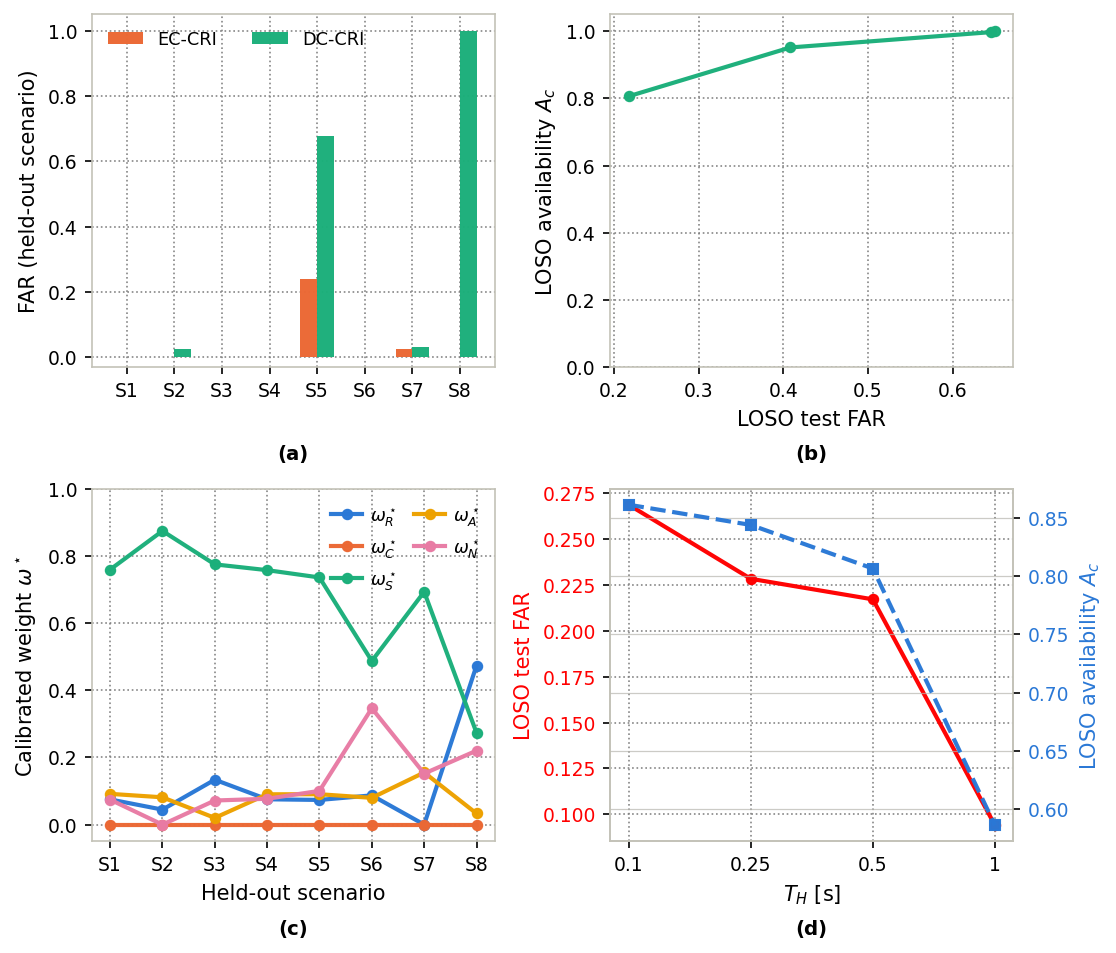

In [16]:
# ======================================================================
# Easy-to-tune figure settings
# Matching Fig_severe_dashboard_v2 conventions
# ======================================================================

FIG_WIDTH = 7.5
FIG_HEIGHT = 6.4

LINE_ALPHA = 0.98
MARKER_SIZE = 4.5
LW_MAIN = 2

FONT_AXIS = 10
FONT_TICK = 9
FONT_LEGEND = 8.5
FONT_PANEL_LABEL = 9.5

GRID_COLOR = "gray"
GRID_ALPHA = 0.95
GRID_LW = 0.80
GRID_LS = ":"

COLOR_ECCRI = plotstyle.STRATEGY_COLORS["threshold"]
COLOR_DCCRI = plotstyle.STRATEGY_COLORS["cri"]
COLOR_DIRECT = plotstyle.STRATEGY_COLORS["direct"]

# Panel (d): use red explicitly for FAR
COLOR_FAR = "red"


def style_grid(ax):
    ax.grid(
        True,
        color=GRID_COLOR,
        alpha=GRID_ALPHA,
        linewidth=GRID_LW,
        linestyle=GRID_LS
    )
    ax.set_axisbelow(True)


def add_panel_label(ax, label):
    """Place panel label centered below each subplot."""
    ax.text(
        0.5, -0.22, label,
        transform=ax.transAxes,
        ha="center",
        va="top",
        fontsize=FONT_PANEL_LABEL,
        fontweight="bold"
    )


# ======================================================================
# Create figure
# ======================================================================

fig, axes = plt.subplots(
    2, 2,
    figsize=(FIG_WIDTH, FIG_HEIGHT)
)

((axA, axB), (axC, axD)) = axes


# ======================================================================
# Panel (a): per-held-out-scenario FAR
# EC-CRI vs DC-CRI, principal settings
# ======================================================================

principal_fold_df = (
    risk_fold_dfs[EPS_RISK_PRINCIPAL]
    .set_index("held_out")
    .reindex(SCENARIO_ORDER)
)

ecri_far_by_scn = (
    pd.read_csv(
        os.path.join(
            RESULTS_DIR,
            "results_dc_cri_loso_perscenario_summary.csv"
        ),
        index_col=[0, 1]
    )["FAR"]
    .xs("EC-CRI", level="method")
    .reindex(SCENARIO_ORDER)
)

x = np.arange(len(SCENARIO_ORDER))
width = 0.35

axA.bar(
    x - width / 2,
    ecri_far_by_scn.values,
    width,
    color=COLOR_ECCRI,
    alpha=LINE_ALPHA,
    label="EC-CRI"
)

axA.bar(
    x + width / 2,
    principal_fold_df["FAR"].values,
    width,
    color=COLOR_DCCRI,
    alpha=LINE_ALPHA,
    label="DC-CRI"
)

axA.set_xticks(x)
axA.set_xticklabels(
    SCENARIO_ORDER,
    fontsize=FONT_TICK
)

axA.set_ylabel(
    "FAR (held-out scenario)",
    fontsize=FONT_AXIS
)

axA.set_ylim(-0.03, 1.05)

axA.legend(
    frameon=False,
    fontsize=FONT_LEGEND,
    ncol=2,
    loc="upper left"
)

style_grid(axA)
add_panel_label(axA, "(a)")


# ======================================================================
# Panel (b): risk-availability trade-off across epsilon_risk
# ======================================================================

axB.plot(
    risk_df["FAR"],
    risk_df["A_c"],
    "o-",
    color=COLOR_DCCRI,
    lw=LW_MAIN,
    markersize=MARKER_SIZE,
    alpha=LINE_ALPHA
)


axB.set_xlabel(
    r"LOSO test FAR",
    fontsize=FONT_AXIS
)

axB.set_ylabel(
    r"LOSO availability $A_c$",
    fontsize=FONT_AXIS
)

axB.set_ylim(0, 1.05)

style_grid(axB)
add_panel_label(axB, "(b)")


# ======================================================================
# Panel (c): calibrated-weight stability across the 8 LOSO folds
# Principal settings
# ======================================================================

fold_omega_df = pd.read_csv(
    os.path.join(
        RESULTS_DIR,
        "results_dc_cri_loso_folds.csv"
    ),
    index_col=0
)

fold_omega_df = fold_omega_df.reindex(SCENARIO_ORDER)

omega_cols = [
    "omega_R",
    "omega_C",
    "omega_S",
    "omega_A",
    "omega_N"
]

# All LOSO-calibrated weights use the starred notation
omega_labels = [
    r"$\omega_R^\star$",
    r"$\omega_C^\star$",
    r"$\omega_S^\star$",
    r"$\omega_A^\star$",
    r"$\omega_N^\star$"
]

omega_colors = [
    plotstyle.INDICATOR_COLORS[k]
    for k in ["RI", "CI", "SMI", "AI", "NCI"]
]

for col, lab, col_color in zip(
    omega_cols,
    omega_labels,
    omega_colors
):
    axC.plot(
        x,
        fold_omega_df[col].values,
        "o-",
        color=col_color,
        lw=LW_MAIN,
        markersize=MARKER_SIZE,
        alpha=LINE_ALPHA,
        label=lab
    )

axC.set_xticks(x)
axC.set_xticklabels(
    SCENARIO_ORDER,
    fontsize=FONT_TICK
)

axC.set_ylabel(
    r"Calibrated weight $\omega^\star$",
    fontsize=FONT_AXIS
)

axC.set_xlabel(
    "Held-out scenario",
    fontsize=FONT_AXIS
)

axC.set_ylim(-0.05, 1.0)

# Legend moved INSIDE the subplot.
# Two columns for a compact journal-style layout.
axC.legend(
    frameon=False,
    fontsize=FONT_LEGEND,
    ncol=2,
    loc="upper right",
    columnspacing=1.0,
    handlelength=1.8,
    handletextpad=0.4
)

style_grid(axC)
add_panel_label(axC, "(c)")


# ======================================================================
# Panel (d): verification-horizon sensitivity
# ======================================================================

xh = np.arange(len(T_H_LEVELS))

axD2 = axD.twinx()

# FAR: RED, left y-axis
axD.plot(
    xh,
    horizon_df["FAR"].values,
    "o-",
    color=COLOR_FAR,
    lw=LW_MAIN,
    markersize=MARKER_SIZE,
    alpha=LINE_ALPHA
)

# Candidate-controller availability: right y-axis
axD2.plot(
    xh,
    horizon_df["A_c"].values,
    "s--",
    color=COLOR_DIRECT,
    lw=LW_MAIN,
    markersize=MARKER_SIZE,
    alpha=LINE_ALPHA
)

axD.set_xticks(xh)

axD.set_xticklabels(
    [f"{t:g}" for t in T_H_LEVELS],
    fontsize=FONT_TICK
)

axD.set_xlabel(
    r"$T_H$ [s]",
    fontsize=FONT_AXIS
)

# Left y-axis: FAR in red
axD.set_ylabel(
    "LOSO test FAR",
    fontsize=FONT_AXIS,
    color=COLOR_FAR
)

# Right y-axis: availability
axD2.set_ylabel(
    r"LOSO availability $A_c$",
    fontsize=FONT_AXIS,
    color=COLOR_DIRECT
)

axD.tick_params(
    axis="y",
    labelcolor=COLOR_FAR
)

axD2.tick_params(
    axis="y",
    labelcolor=COLOR_DIRECT,
    labelsize=FONT_TICK
)

# No legend is required:
# the colored left/right y-axis labels identify both curves directly.

style_grid(axD)
add_panel_label(axD, "(d)")


# ======================================================================
# Common formatting
# ======================================================================

for ax in [axA, axB, axC, axD]:
    ax.tick_params(labelsize=FONT_TICK)

# Extra vertical spacing is required because panel labels
# are now positioned underneath each subplot.
plt.tight_layout(
    h_pad=2.2,
    w_pad=1.5
)

plotstyle.savefig(
    fig,
    os.path.join(
        FIG_DIR,
        "Fig_dc_cri_loso_summary_V2.pdf"
    )
)

plt.show()

## Representative trajectory: EC-CRI vs. DC-CRI on S8 (held-out fold, principal settings)

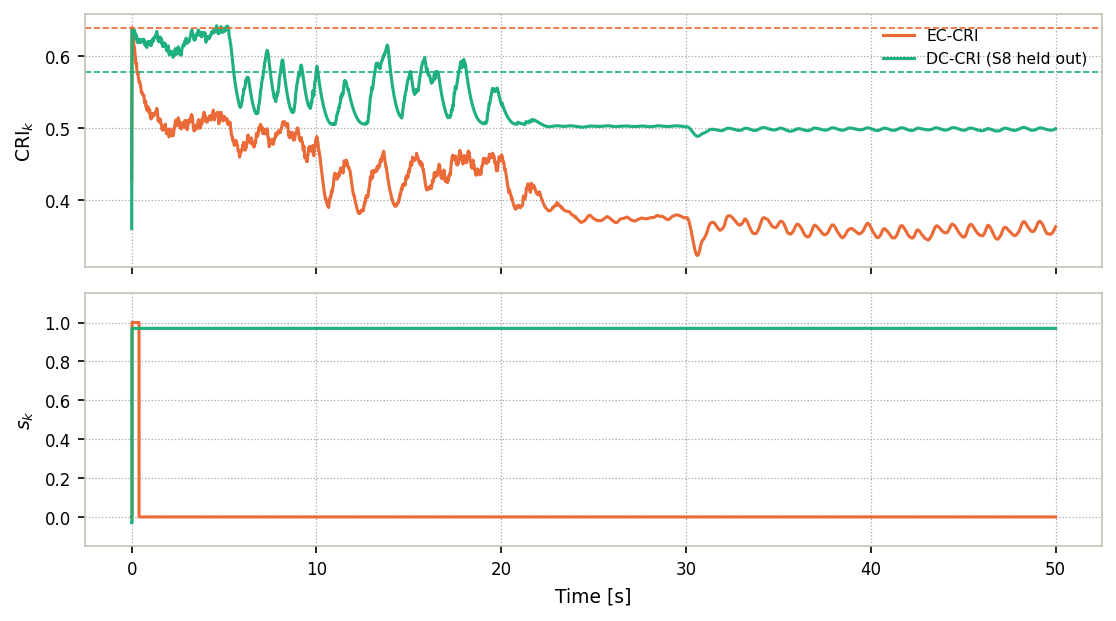

EC-CRI  eta_A=0.640  mean s=0.0076
DC-CRI  eta_A=0.578  mean s=0.9996  omega=[0.473 0.    0.273 0.033 0.22 ]


In [6]:
pool_no_s8 = [t for name in SCENARIO_ORDER if name != "S8" for t in cal_traj_Hprincipal[name]]
outcome_s8 = dcc.calibrate_dc_cri(pool_no_s8, H=H_principal, eps_risk=EPS_RISK_PRINCIPAL,
                                   lambda_H=LAMBDA_H, crip_template=crip)
crip_dc_s8 = dcc.dc_cri_params_from_outcome(outcome_s8, crip)

s8 = scenarios.build_S8(pp, prof, T_end=50.0)
simp_ec = SimulationParams(T_end=s8.T_end, seed=1, strategy="cri")
lg_ec = sim.run_closed_loop(s8, pp, cp, cons, crip, probep, simp_ec)
lg_dc = sim.run_closed_loop(s8, pp, cp, cons, crip_dc_s8, probep, simp_ec)

fig2, axes2 = plt.subplots(2, 1, figsize=(FIG_WIDTH, 4.2), sharex=True)
axes2[0].plot(lg_ec["t"], lg_ec["CRI"], color=COLOR_ECCRI, lw=LW_MAIN, alpha=LINE_ALPHA, label="EC-CRI")
axes2[0].plot(lg_dc["t"], lg_dc["CRI"], color=COLOR_DCCRI, lw=LW_MAIN, alpha=LINE_ALPHA, label="DC-CRI (S8 held out)")
axes2[0].axhline(crip.eta_A, color=COLOR_ECCRI, lw=0.8, ls="--")
axes2[0].axhline(outcome_s8.eta_A, color=COLOR_DCCRI, lw=0.8, ls="--")
axes2[0].set_ylabel("$\\mathrm{CRI}_k$", fontsize=FONT_AXIS)
axes2[0].legend(frameon=False, fontsize=FONT_LEGEND, loc="upper right")
style_grid(axes2[0])

axes2[1].step(lg_ec["t"], lg_ec["s"], where="post", color=COLOR_ECCRI, lw=LW_MAIN, alpha=LINE_ALPHA, label="EC-CRI")
axes2[1].step(lg_dc["t"], lg_dc["s"] - 0.03, where="post", color=COLOR_DCCRI, lw=LW_MAIN, alpha=LINE_ALPHA, label="DC-CRI")
axes2[1].set_ylabel("$s_k$", fontsize=FONT_AXIS)
axes2[1].set_xlabel("Time [s]", fontsize=FONT_AXIS)
axes2[1].set_ylim(-0.15, 1.15)
style_grid(axes2[1])

for ax in axes2:
    ax.tick_params(labelsize=FONT_TICK)

plt.tight_layout()
plotstyle.savefig(fig2, os.path.join(FIG_DIR, "Fig_dc_cri_representative_trajectory.pdf"))
plt.show()

print(f"EC-CRI  eta_A={crip.eta_A:.3f}  mean s={lg_ec['s'].mean():.4f}")
print(f"DC-CRI  eta_A={outcome_s8.eta_A:.3f}  mean s={lg_dc['s'].mean():.4f}  omega={outcome_s8.omega.round(3)}")

## Takeaway

The risk-tolerance sweep shows the intended engineering trade-off under genuine LOSO evaluation,
not merely in-sample: tightening $\epsilon_{\mathrm{risk}}$ raises the calibrated $\eta_A^\star$,
lowers the out-of-scenario FAR, and reduces availability; loosening it does the opposite. All four
risk levels were calibration-feasible in all 8 folds. Critically, the LOSO test FAR is *not*
monotonic and smooth the way in-sample risk is -- there is a sharp generalization transition
between $\epsilon_{\mathrm{risk}}=0.01$ (good generalization on 6/8 folds) and the looser settings
(poor generalization on most folds), because the calibration pool's hazard samples are dominated by
S7/S8's collapse-type events, and a threshold barely conservative enough for that specific pool does
not automatically transfer to a qualitatively different hazard mechanism (e.g. S2's gradual
constraint approach). This is the central, honest finding of the sensitivity study -- see
`LaTeX_Edit_Add_V2.ipynb` for the full discussion and suggested paper text.